[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abhishek12198/entriMiniProject/blob/main/Intermediate_Assessment_Car_Price.ipynb)

# Car price regression

Open this notebook in Google Colab with the button above, then use **Runtime → Run all**. Each code cell runs in order, and the tables and plots appear under that cell.

A car company wants to know which measurements move the price of a car in the American market, and how closely those measurements track the price. The target is `price`. Everything else is treated as an input the company can observe on a car: size, weight, engine, fuel economy, body style, and brand.

Five regressors are trained on one shared holdout. They are compared with R-squared, mean squared error, and mean absolute error. The best of the five is then retuned on the training cars only, and scored again on the same holdout. The stack is scikit-learn, pandas, NumPy, and Matplotlib.


## 1. Setup


In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.svm import SVR


## 2. Load the dataset

The table is the market survey linked in the assessment. If this notebook is running next to `data/CarPrice.csv`, that file is read. In Colab the same file is downloaded from the shared Drive link.

Each row is one car. `car_ID` is only a row number. `CarName` starts with the brand and then a model name. `price` is the amount to predict, in dollars.


In [2]:
local_candidates = [Path("data/CarPrice.csv"), Path("CarPrice.csv")]
source = next((path for path in local_candidates if path.exists()), None)
if source is None:
    source = "https://drive.google.com/uc?export=download&id=1FHmYNLs9v0Enc-UExEMpitOFGsWvB2dP"

cars = pd.read_csv(source)
print(f"Source: {source}")
print(f"Rows: {cars.shape[0]}")
print(f"Columns: {cars.shape[1]}")
print(f"Price: min ${cars['price'].min():,.0f}, median ${cars['price'].median():,.0f}, max ${cars['price'].max():,.0f}")
cars.head(3)


Source: data/CarPrice.csv
Rows: 205
Columns: 26
Price: min $5,118, median $10,295, max $45,400


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0


## 3. Preprocessing

Five cleaning steps are applied before any model is fit.

`car_ID` is dropped. It counts rows. A model that used it would be memorising the survey order, not learning a price.

`CarName` is split into a brand. The survey spells five brands more than one way: `maxda`, `porcshce`, `toyouta`, `vw`, and `vokswagen`. Those spellings are mapped to mazda, porsche, toyota, and volkswagen. The model name after the brand is dropped. With 205 cars, a separate column for every model name would be a label for one or two rows.

`doornumber` and `cylindernumber` are stored as words (`four`, `six`, `twelve`). They are real counts, so they are mapped to integers. A door count of 4 is then twice a door count of 2, which a one-hot encoding would not say.

The remaining text columns are one-hot encoded. `drop_first=True` removes one level of each column so a linear model is not given a redundant copy of the same information. The tree models use this same table.

There is no separate scaling step yet. Linear regression and the support vector regressor standardise columns inside a pipeline that is fit on the training cars only. A tree splits one column at a time, and a per-column rescaling does not change which cars fall on each side of a split, so the tree models keep the original units.


In [3]:
missing = int(cars.isna().sum().sum())
duplicate_rows = int(cars.duplicated().sum())
print(f"Missing values: {missing} of {cars.shape[0] * cars.shape[1]}")
print(f"Duplicate rows: {duplicate_rows}")

brand_fix = {
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vw": "volkswagen",
    "vokswagen": "volkswagen",
}
raw_brand = cars["CarName"].str.split().str[0].str.lower()
print()
print("Brand spellings corrected:")
print(raw_brand[raw_brand.isin(brand_fix)].value_counts().to_string())

word_to_num = {
    "two": 2,
    "three": 3,
    "four": 4,
    "five": 5,
    "six": 6,
    "eight": 8,
    "twelve": 12,
}
model_frame = cars.copy()
model_frame["brand"] = raw_brand.replace(brand_fix)
model_frame["doors"] = model_frame["doornumber"].map(word_to_num)
model_frame["cylinders"] = model_frame["cylindernumber"].map(word_to_num)
model_frame = model_frame.drop(columns=["car_ID", "CarName", "doornumber", "cylindernumber"])

unmapped = int(model_frame["doors"].isna().sum() + model_frame["cylinders"].isna().sum())
print()
print(f"Door or cylinder values left unmapped: {unmapped}")
print(f"Brands after the spelling fix: {model_frame['brand'].nunique()}")

y = model_frame["price"]
X = pd.get_dummies(model_frame.drop(columns=["price"]), drop_first=True)
print(f"Feature matrix: {X.shape[0]} rows, {X.shape[1]} columns")


Missing values: 0 of 5330
Duplicate rows: 0

Brand spellings corrected:
CarName
maxda        2
vw           2
porcshce     1
toyouta      1
vokswagen    1

Door or cylinder values left unmapped: 0
Brands after the spelling fix: 22
Feature matrix: 205 rows, 59 columns


## 4. What moves with price, before any model

The correlations below use the numeric columns only, on all 205 cars. They are a description of the table, not a fitted model. A positive number means the column and the price rise together.

Engine size, curb weight, horsepower, and car width rise with price. Highway and city fuel economy fall as price rises, because the heavier and more powerful cars use more fuel. These columns also rise and fall together, so a later model that leans on engine size is partly using the same information as weight and horsepower.


highwaympg         -0.698
citympg            -0.686
peakrpm            -0.085
symboling          -0.080
doors               0.032
compressionratio    0.068
stroke              0.079
carheight           0.119
boreratio           0.553
wheelbase           0.578
carlength           0.683
cylinders           0.718
carwidth            0.759
horsepower          0.808
curbweight          0.835
enginesize          0.874


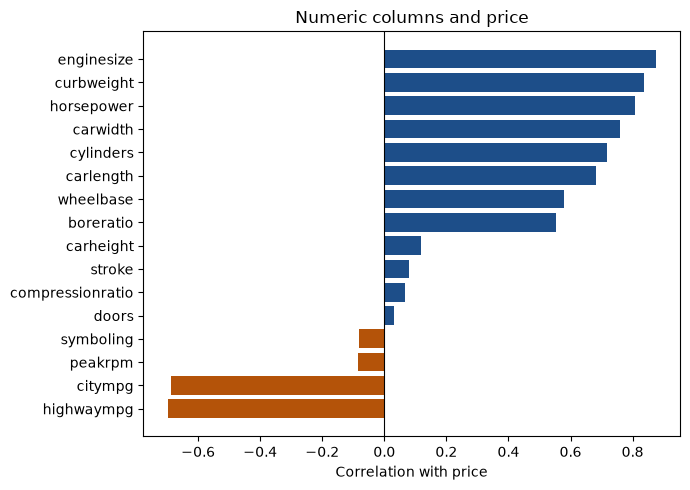

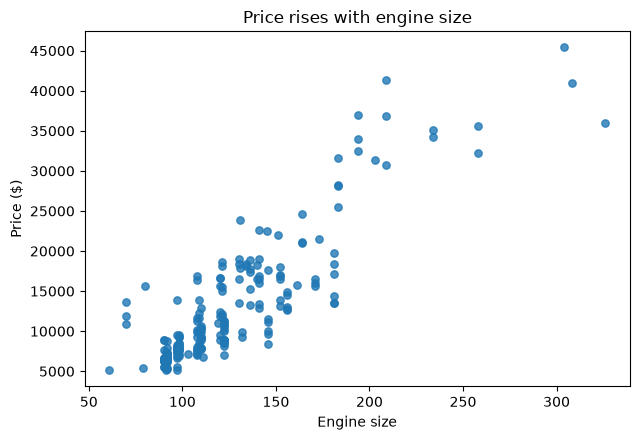

In [4]:
numeric_columns = [
    "symboling", "wheelbase", "carlength", "carwidth", "carheight", "curbweight",
    "enginesize", "boreratio", "stroke", "compressionratio", "horsepower", "peakrpm",
    "citympg", "highwaympg", "doors", "cylinders", "price",
]
correlation = model_frame[numeric_columns].corr()["price"].drop("price").sort_values()
print(correlation.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#b45309" if value < 0 else "#1d4e89" for value in correlation]
ax.barh(correlation.index, correlation.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with price")
ax.set_title("Numeric columns and price")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(model_frame["enginesize"], model_frame["price"], s=28, alpha=0.8)
ax.set_xlabel("Engine size")
ax.set_ylabel("Price ($)")
ax.set_title("Price rises with engine size")
fig.tight_layout()
plt.show()


## 5. One shared holdout

Every model uses the same split: 20% of the cars held out, `random_state=42`. That is 164 training cars and 41 test cars. The test cars are not used to fit a model or to choose tuning settings. They are used only for the comparison tables.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Training cars: {len(X_train)}")
print(f"Test cars: {len(X_test)}")
print(f"Training price mean: ${y_train.mean():,.0f}")
print(f"Test price mean: ${y_test.mean():,.0f}")


Training cars: 164
Test cars: 41
Training price mean: $13,223
Test price mean: $13,490


## 6. The five regressors

Each model is fit on the training cars and scored on the 41 test cars.

- **R-squared** is the share of price variation the predictions capture. A value of 1 would be a perfect match. A value below 0 is worse than predicting the training average for every car.
- **Mean squared error** is the average squared dollar error. Large misses count more than small ones, and the units are dollars squared.
- **Mean absolute error** is the average absolute dollar error. It is the typical miss in dollars.
- **Root mean squared error** is the square root of MSE, so it can be read in dollars as well. It is shown beside MSE because the squared figure is hard to compare with a sticker price.

**Linear regression** predicts price as a weighted sum of the columns. The weights are the size of each column's association once the others are held constant. The columns are standardised in the pipeline, so a weight is the dollar change for a one-standard-deviation move. This is a reasonable first model: several of the strong columns, especially engine size, move with price in a fairly straight line.

**A decision tree** repeatedly splits one column, such as engine size above or below a cut, and predicts the average training price in the leaf a car reaches. The cuts can follow a step that a single straight line misses. One tree also memorizes the particular cars it was grown on.

**A random forest** grows 200 trees on bootstrap samples of the training cars and averages their predictions. The average keeps the tree's ability to use engine size, weight, and brand together, and it drops splits that only fit one sample. That is the useful property on a table of 164 cars with several columns that describe the same large, powerful cars.

**Gradient boosting** builds trees one after another. Each new tree fits the remaining dollar error of the trees before it. The defaults use a learning rate of 0.1 and trees of depth 3. It is a second way to combine trees, with less averaging and more attention to the cars the model still gets wrong.

**A support vector regressor** fits a function that stays within a margin of the training prices, using an RBF kernel so the function can curve. The pipeline standardises the inputs. The default margin is 0.1 and the default penalty is `C=1`. Prices here run from about $5,000 to about $45,000, so a margin of ten cents is not a meaningful tolerance on a sticker price. The defaults are still the ones scored in the comparison. Whether a retuned version would close the gap is a separate question from this first pass.


In [6]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Support Vector Regressor": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR()),
    ]),
}

rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    mse = mean_squared_error(y_test, predicted)
    rows.append({
        "model": name,
        "r2": r2_score(y_test, predicted),
        "mse": mse,
        "rmse": np.sqrt(mse),
        "mae": mean_absolute_error(y_test, predicted),
    })

results = pd.DataFrame(rows).sort_values("r2", ascending=False)
printable = results.copy()
printable["r2"] = printable["r2"].map(lambda value: f"{value:.4f}")
printable["mse"] = printable["mse"].map(lambda value: f"{value:,.0f}")
printable["rmse"] = printable["rmse"].map(lambda value: f"{value:,.0f}")
printable["mae"] = printable["mae"].map(lambda value: f"{value:,.0f}")
printable = printable.rename(columns={
    "model": "Model",
    "r2": "R-squared",
    "mse": "MSE",
    "rmse": "RMSE ($)",
    "mae": "MAE ($)",
})
print(printable.to_string(index=False))


                   Model R-squared        MSE RMSE ($) MAE ($)
           Random Forest    0.9592  3,223,443    1,795   1,252
       Gradient Boosting    0.9291  5,596,060    2,366   1,663
           Decision Tree    0.8983  8,028,699    2,833   1,956
       Linear Regression    0.8951  8,283,566    2,878   1,942
Support Vector Regressor   -0.1008 86,898,073    9,322   5,702


## 7. Which model describes price best

On the 41 test cars the random forest is ahead on every requested metric. R-squared is 0.9592, so the predictions capture about 96% of the price variation in that holdout. The mean absolute error is about $1,252. The next model, gradient boosting, is at 0.9291 and about $1,663. Linear regression and the single tree are close to each other, near 0.90 and about $1,950. The untuned support vector regressor is last, with a negative R-squared: its default margin does not fit a price measured in thousands of dollars, so it loses to a flat prediction.

The forest is the model to keep. Averaging 200 trees is what separates it from the single tree, which can cut the training cars apart and still miss by more on the holdout. It also beats the linear sum because engine size, weight, and brand do not add up in exactly the same way in every part of the price range. The plot below compares the forest's predictions with the actual test prices. The dashed line is a perfect prediction.


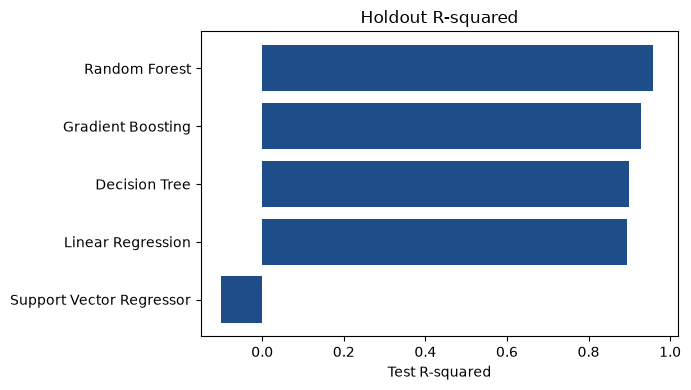

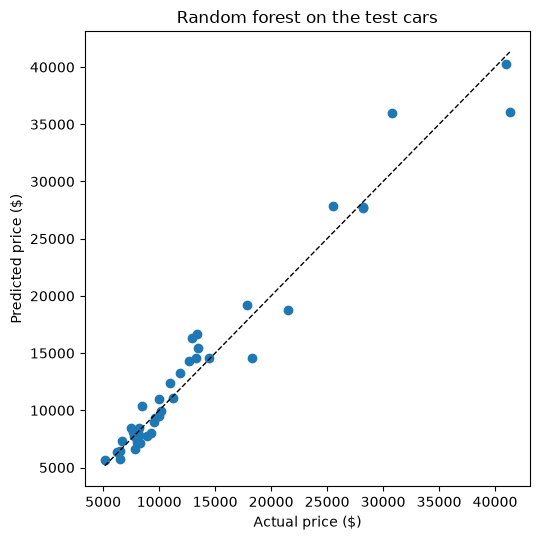

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
order = results.sort_values("r2")
ax.barh(order["model"], order["r2"], color="#1d4e89")
ax.set_xlabel("Test R-squared")
ax.set_xlim(min(0, order["r2"].min()) - 0.05, 1.02)
ax.set_title("Holdout R-squared")
fig.tight_layout()
plt.show()

forest_prediction = predictions["Random Forest"]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, forest_prediction, s=36)
low = min(y_test.min(), forest_prediction.min())
high = max(y_test.max(), forest_prediction.max())
ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Actual price ($)")
ax.set_ylabel("Predicted price ($)")
ax.set_title("Random forest on the test cars")
fig.tight_layout()
plt.show()


## 8. Which variables matter

The forest's impurity importance is the share of the training fit that comes from splits on that column. Engine size accounts for about 59% of that fit, and curb weight for about 27%. Highway fuel economy, horsepower, and the car's width and length follow, well behind those two. Among the brand columns, BMW is the largest, and it is still near 1%.

This lines up with the correlations in section 4. A larger engine and a heavier car are the measurements that track a higher price. Fuel economy tracks a lower price because it is the other side of the same cars. Brand is real, but in this survey it is a small addition once size and the engine are known. For the design question the company asked, the variables worth changing first are engine size, weight, horsepower, and the related body width. A pricing rule that ignored those and used only the badge would miss most of the price.


Largest shares of the random-forest fit:
enginesize    0.5861
curbweight    0.2679
highwaympg    0.0458
horsepower    0.0200
carwidth      0.0123
carlength     0.0089
wheelbase     0.0072
brand_bmw     0.0072
citympg       0.0068
peakrpm       0.0058
boreratio     0.0043
cylinders     0.0042


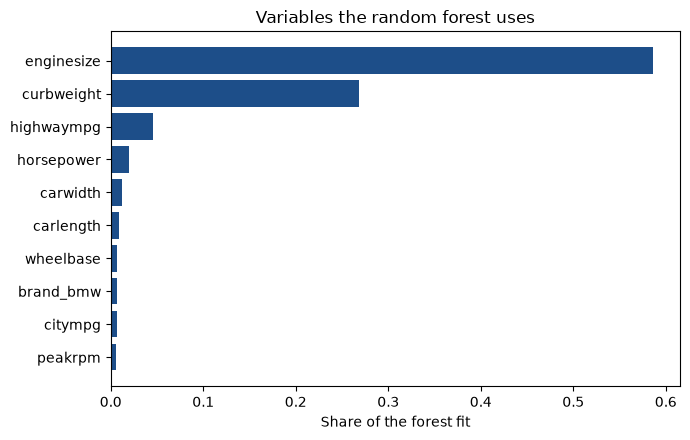

In [8]:
forest = models["Random Forest"]
importance = pd.Series(forest.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
print("Largest shares of the random-forest fit:")
print(importance.head(12).map(lambda value: f"{value:.4f}").to_string())

top = importance.head(10).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color="#1d4e89")
ax.set_xlabel("Share of the forest fit")
ax.set_title("Variables the random forest uses")
fig.tight_layout()
plt.show()


## 9. Hyperparameter tuning

The forest above uses 200 trees, no depth limit, a minimum of one car in a leaf, and every column available at each split. The search below tries a small grid around that setting: 200 or 400 trees, a depth cap of 8 or 16 or no cap, a leaf size of 1 or 2, and either every column or a random subset of columns at each split. That is 24 combinations. Each one is scored by 5-fold R-squared on the training cars only. The 41 test cars are not used to pick the winner.

The combination with the best training-fold R-squared is then scored once on the test cars, next to the original forest.


In [9]:
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 8, 16],
    "min_samples_leaf": [1, 2],
    "max_features": [1.0, "sqrt"],
}
search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
)
search.fit(X_train, y_train)
print("Chosen settings:", search.best_params_)
print(f"Best 5-fold training R-squared: {search.best_score_:.4f}")

tuned_prediction = search.predict(X_test)
tuned_mse = mean_squared_error(y_test, tuned_prediction)
original = results.loc[results["model"] == "Random Forest"].iloc[0]
comparison = pd.DataFrame([
    {
        "model": "Random forest, original",
        "r2": original["r2"],
        "mse": original["mse"],
        "rmse": original["rmse"],
        "mae": original["mae"],
    },
    {
        "model": "Random forest, tuned",
        "r2": r2_score(y_test, tuned_prediction),
        "mse": tuned_mse,
        "rmse": np.sqrt(tuned_mse),
        "mae": mean_absolute_error(y_test, tuned_prediction),
    },
])
show = comparison.copy()
show["r2"] = show["r2"].map(lambda value: f"{value:.4f}")
show["mse"] = show["mse"].map(lambda value: f"{value:,.0f}")
show["rmse"] = show["rmse"].map(lambda value: f"{value:,.0f}")
show["mae"] = show["mae"].map(lambda value: f"{value:,.0f}")
show = show.rename(columns={
    "model": "Model",
    "r2": "R-squared",
    "mse": "MSE",
    "rmse": "RMSE ($)",
    "mae": "MAE ($)",
})
print()
print(show.to_string(index=False))


Chosen settings: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 400}
Best 5-fold training R-squared: 0.9080

                  Model R-squared       MSE RMSE ($) MAE ($)
Random forest, original    0.9592 3,223,443    1,795   1,252
   Random forest, tuned    0.9351 5,122,404    2,263   1,378


## 10. Did tuning help?

No. The search keeps 400 trees, a depth limit of 8, and a random subset of columns at each split, because that combination has the highest 5-fold R-squared on the training cars (0.908). On the same test cars as section 7, that forest falls to R-squared 0.935 and a mean absolute error of about $1,378. The original forest remains at 0.959 and about $1,252.

The searched settings hold back the column the table depends on. A random subset of features often leaves engine size out of a split, and engine size is most of the fit in section 8. The cross-validation score liked that extra restraint. The holdout did not. The model reported to the company is the original random forest of 200 trees.

Taken together, the answer to the two business questions is:

- The variables that matter are engine size first, then curb weight, then highway fuel economy, horsepower, and car width. Brand is a smaller remaining difference.
- Those variables describe the holdout prices well. The forest captures about 96% of the price variation on cars it was not trained on, and a typical prediction is off by about $1,250.
